# From a group comparison to a brain map

PIE's imaging analyses are **regional**: one number per structure (a volume, a thickness, a binding ratio), compared
between groups. This walkthrough turns a table of such results into

1. a **statistic map**, painted on a FastSurfer label atlas on the atlas's own grid (no warping);
2. an **overlay in the Brain Explorer**, declared `verified` because it shares its reference scan's grid;
3. **publication figures** (slices, glass brain, cortical surface) drawn from the same file, so the figure and the
   interactive view cannot disagree.

**Data.** The canvas is the MNI152NLin2009cAsym template (TemplateFlow), segmented with FastSurfer by
`scripts/fetch_viewer_examples.py`. The numbers are **synthetic: not a result**. They are simulated below from a seed
so that the notebook runs anywhere, without PPMI access. No PPMI data appear in this notebook.

In [1]:
import json
import os
import shutil
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.multitest import multipletests

REPO = Path.cwd() if (Path.cwd() / "pie").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO))
os.chdir(REPO)                                   # every path below is relative to the repository
from pie.imaging import regionmap
from pie.stats.compare import welch_ttest

EXAMPLES = Path("Imaging/examples")
TEMPLATE_FS = EXAMPLES / "fastsurfer" / "MNI152NLin2009cAsym"
ATLAS = TEMPLATE_FS / "mri" / "aparc.DKTatlas+aseg.deep.mgz"
OUT = EXAMPLES / "derived" / "statmaps"
OUT.mkdir(parents=True, exist_ok=True)
assert ATLAS.is_file(), "Run scripts/fetch_viewer_examples.py and the template FastSurfer command it prints first."
print("template atlas:", ATLAS)

template atlas: Imaging/examples/fastsurfer/MNI152NLin2009cAsym/mri/aparc.DKTatlas+aseg.deep.mgz


## 1. A results table

In a real analysis the table comes from PIE's imaging-derived phenotypes, for example (not executed here):

```python
idps = pd.read_csv("fastsurfer_idps.csv")               # one row per session, columns vol_* / cth_*
rows = []
for col in [c for c in idps if c.startswith("vol_")]:     # one measure per map: thickness (cth_) gets its own table
    r = welch_ttest(idps.loc[idps.group == "PD", col], idps.loc[idps.group == "HC", col])
    rows.append({"feature": col, "d": r["cohens_d"], "p": r["p_value"]})
table = pd.DataFrame(rows)
table["p_fdr"] = multipletests(table["p"], method="fdr_bh")[1]
```

(Adjust for age, sex and eTIV as your design requires; the map only displays what the table says. Keep one measure per map: `vol_ctx_lh_precentral` and `cth_lh_precentral` are the same region, and `region_map` refuses a table that has both.)

Here the two groups are **simulated**: 150 + 150 fake participants per region, with a few regions shifted up or down.
Two columns that are not atlas regions (`eTIV`, `sum_Putamen`) are included to show how unmatched features are reported.

In [2]:
rng = np.random.default_rng(20261015)
lut = pd.read_csv("pie/imaging/viewer/atlas.tsv", sep="\t")
features = ["vol_" + n.replace("-", "_") for n in lut.loc[lut.ID != 0, "LabelName"]] + ["eTIV", "sum_Putamen"]
shift = {"vol_Left_Putamen": -0.7, "vol_Right_Putamen": -0.6, "vol_Left_Lateral_Ventricle": 0.6,
         "vol_ctx_lh_precentral": 0.5, "vol_ctx_rh_insula": -0.5}
rows = []
for f in features:
    r = welch_ttest(rng.normal(shift.get(f, 0.0), 1, 150), rng.normal(0, 1, 150))
    rows.append({"feature": f, "d": r["cohens_d"], "p": r["p_value"]})
table = pd.DataFrame(rows)
table["p_fdr"] = multipletests(table["p"], method="fdr_bh")[1]
table.to_csv(OUT / "synthetic_effects.csv", index=False)
print("synthetic: not a result")
table.sort_values("p").head(8).round(4)

synthetic: not a result


,feature,d,p,p_fdr
1,vol_Left_Lateral_Ventricle,0.7317,0.0000,0.0000
54,vol_ctx_lh_precentral,0.6496,0.0000,0.0000
94,vol_ctx_rh_insula,-0.5983,0.0000,0.0000
25,vol_Right_Putamen,-0.5650,0.0000,0.0000
7,vol_Left_Putamen,-0.5427,0.0000,0.0001
87,vol_ctx_rh_parstriangularis,0.2716,0.0193,0.3122
19,vol_Right_Lateral_Ventricle,0.2506,0.0308,0.3394
41,vol_ctx_lh_lateraloccipital,-0.2495,0.0315,0.3394


## 2. The region map

`region_map` matches feature names to atlas labels (`vol_Left_Putamen` → `Left-Putamen`, `cth_lh_precentral` →
`ctx-lh-precentral`), keeps the regions that pass the threshold, and paints their values. The sidecar records what was
shown and why.

In [3]:
img, side = regionmap.region_map(table, ATLAS, value="d", p="p_fdr", alpha=0.05,
                                 statistic="Cohen's d (synthetic group A - B)", units="SD")
side_view = {k: v for k, v in side.items() if k != "atlas"}
print(json.dumps(side_view, indent=1))

{
 "statistic": "Cohen's d (synthetic group A - B)",
 "units": "SD",
 "value_column": "d",
 "threshold": {
  "p_column": "p_fdr",
  "alpha": 0.05
 },
 "vmax": 0.7316840313624954,
 "n_matched": 95,
 "n_shown": 5,
 "unmatched": [
  "eTIV",
  "sum_Putamen"
 ],
 "source_sha256": "1f335e28cecdc4d972340e0bcbb3241c7b1f7b831ef628082e9b50a3f00a4a92"
}


## 3. The interactive view

The command line writes the map and its sidecar and adds the map to a **copy** of the example manifest, as a
verified overlay on the template (`--reference-id mni152-t1`). Re-running it replaces the entry rather than adding a
second one.

In [4]:
manifest = EXAMPLES / "manifest_statmaps.json"
shutil.copy(EXAMPLES / "manifest.json", manifest)
regionmap.main(["--table", str(OUT / "synthetic_effects.csv"), "--value", "d", "--p", "p_fdr", "--alpha", "0.05",
                "--fastsurfer-dir", str(TEMPLATE_FS), "--out", str(OUT / "synthetic_effects"),
                "--statistic", "Cohen's d (synthetic group A - B)", "--units", "SD",
                "--manifest", str(manifest), "--reference-id", "mni152-t1"])
print("\nServe it:\n  venv_imaging/bin/python -m pie.imaging.viewer serve --manifest", manifest)

Imaging/examples/derived/statmaps/synthetic_effects.nii.gz: 5 of 95 matched regions shown; 2 features unmatched

Serve it:
  venv_imaging/bin/python -m pie.imaging.viewer serve --manifest Imaging/examples/manifest_statmaps.json


Then open http://127.0.0.1:8765, choose **MNI152-template**, open **Registered overlay** in the inspector and pick
the map. Warm regions are positive, cool regions negative; the colour bar uses the sidecar's symmetric limits. The
camera button exports the view as a PNG with a provenance header.

## 4. Figures for a manuscript

`figures` draws ortho slices for any map, and for template maps a glass brain and an fsaverage5 surface view
(downloaded by nilearn on first use). SVGs keep editable text.

['synthetic_effects_slices.png', 'synthetic_effects_slices.svg', 'synthetic_effects_glass.png', 'synthetic_effects_glass.svg', 'synthetic_effects_surface.png']


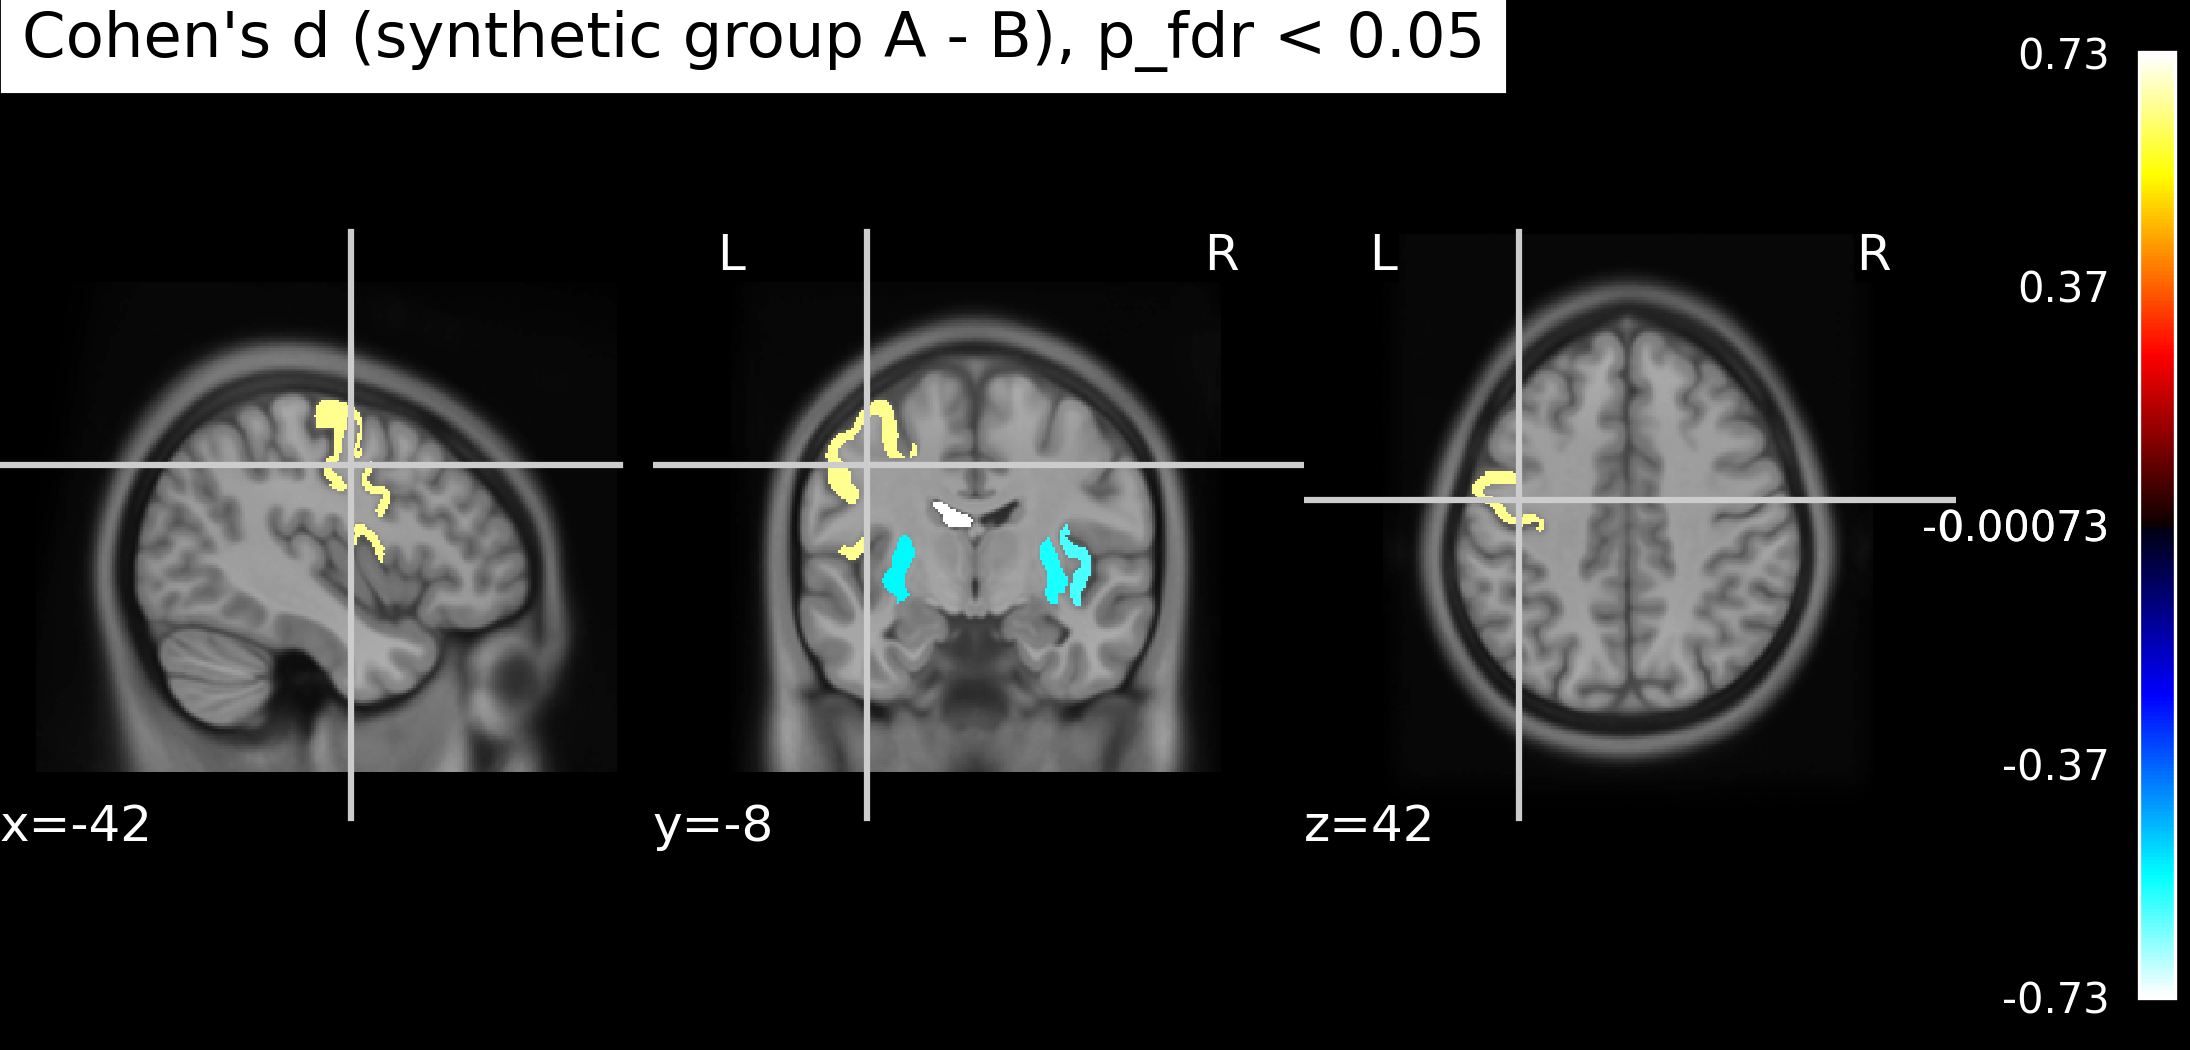

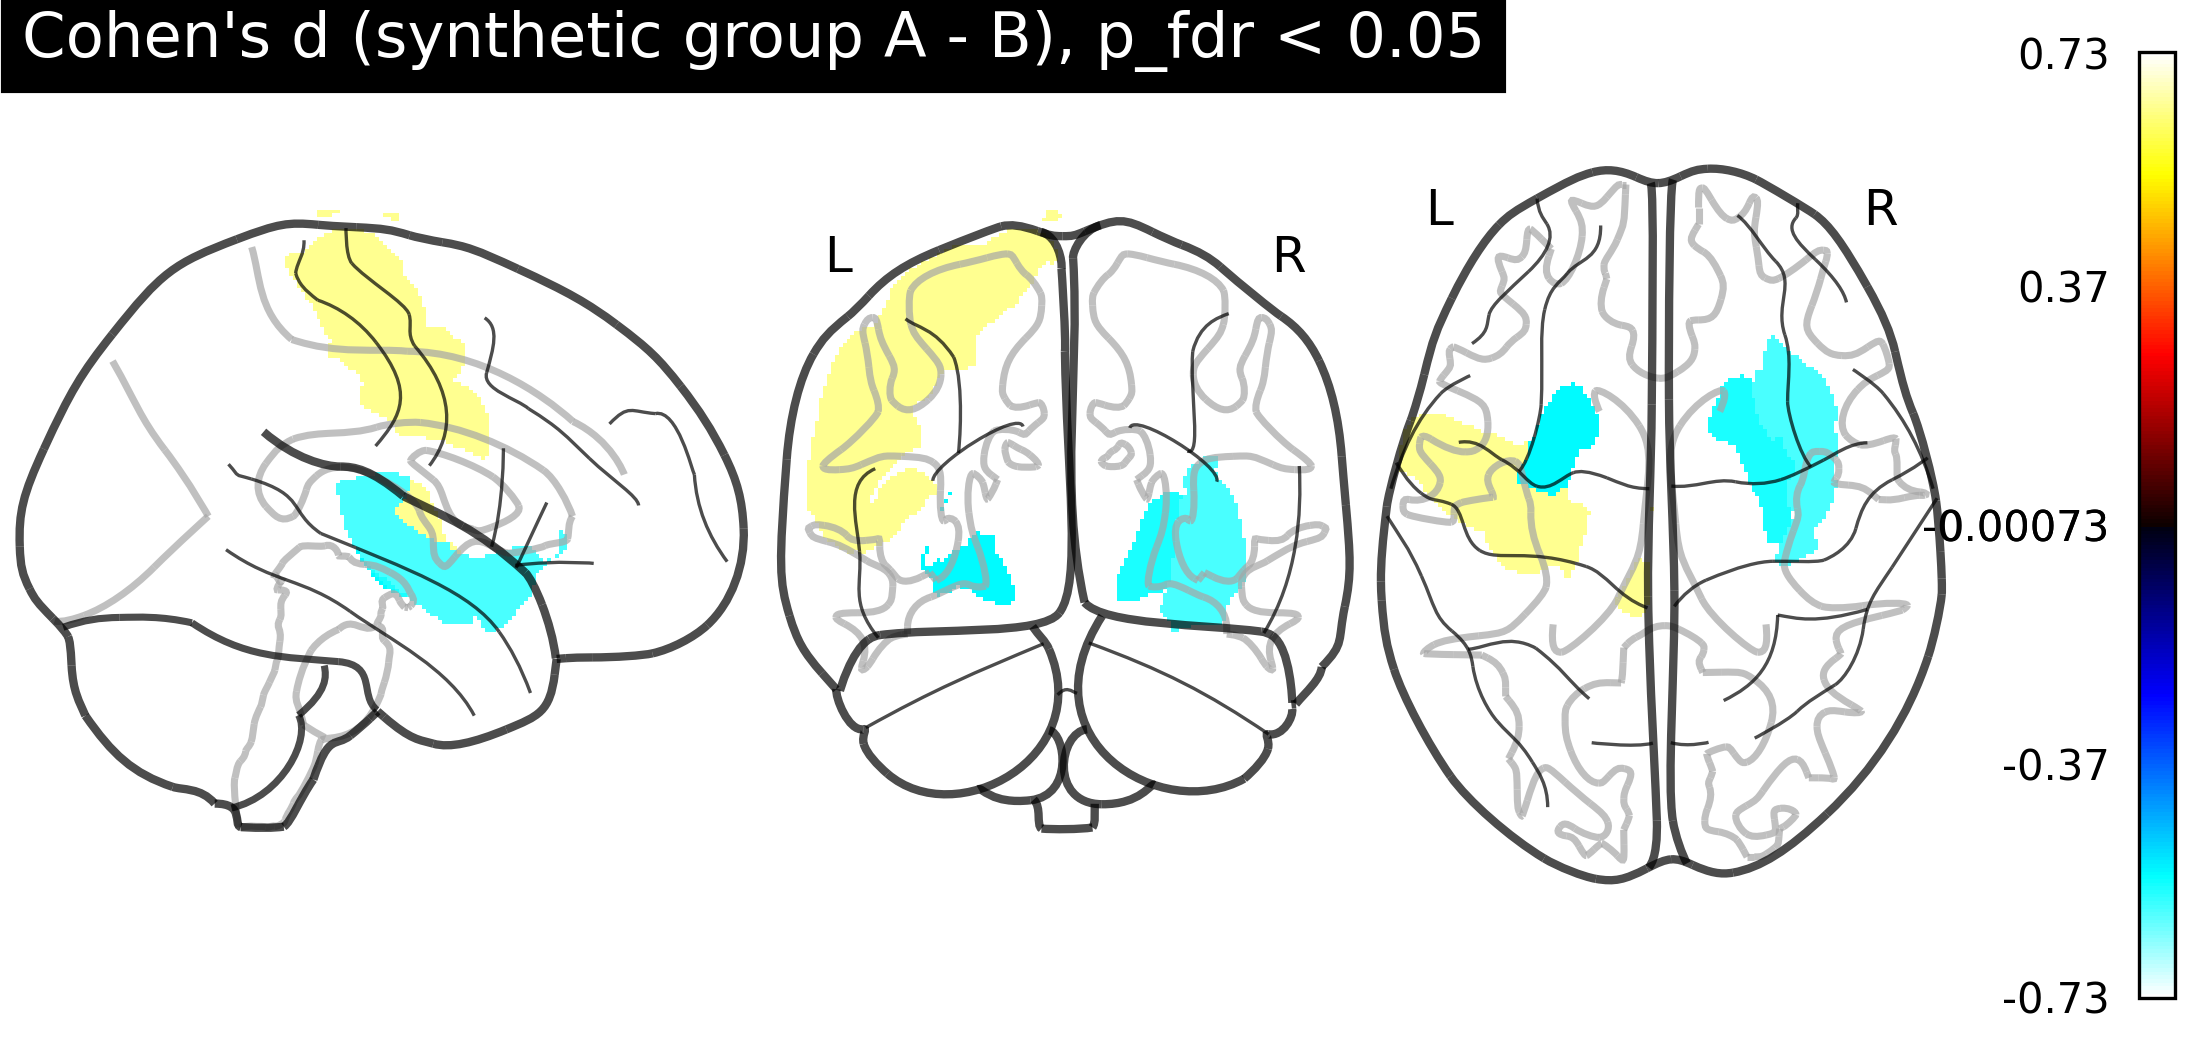

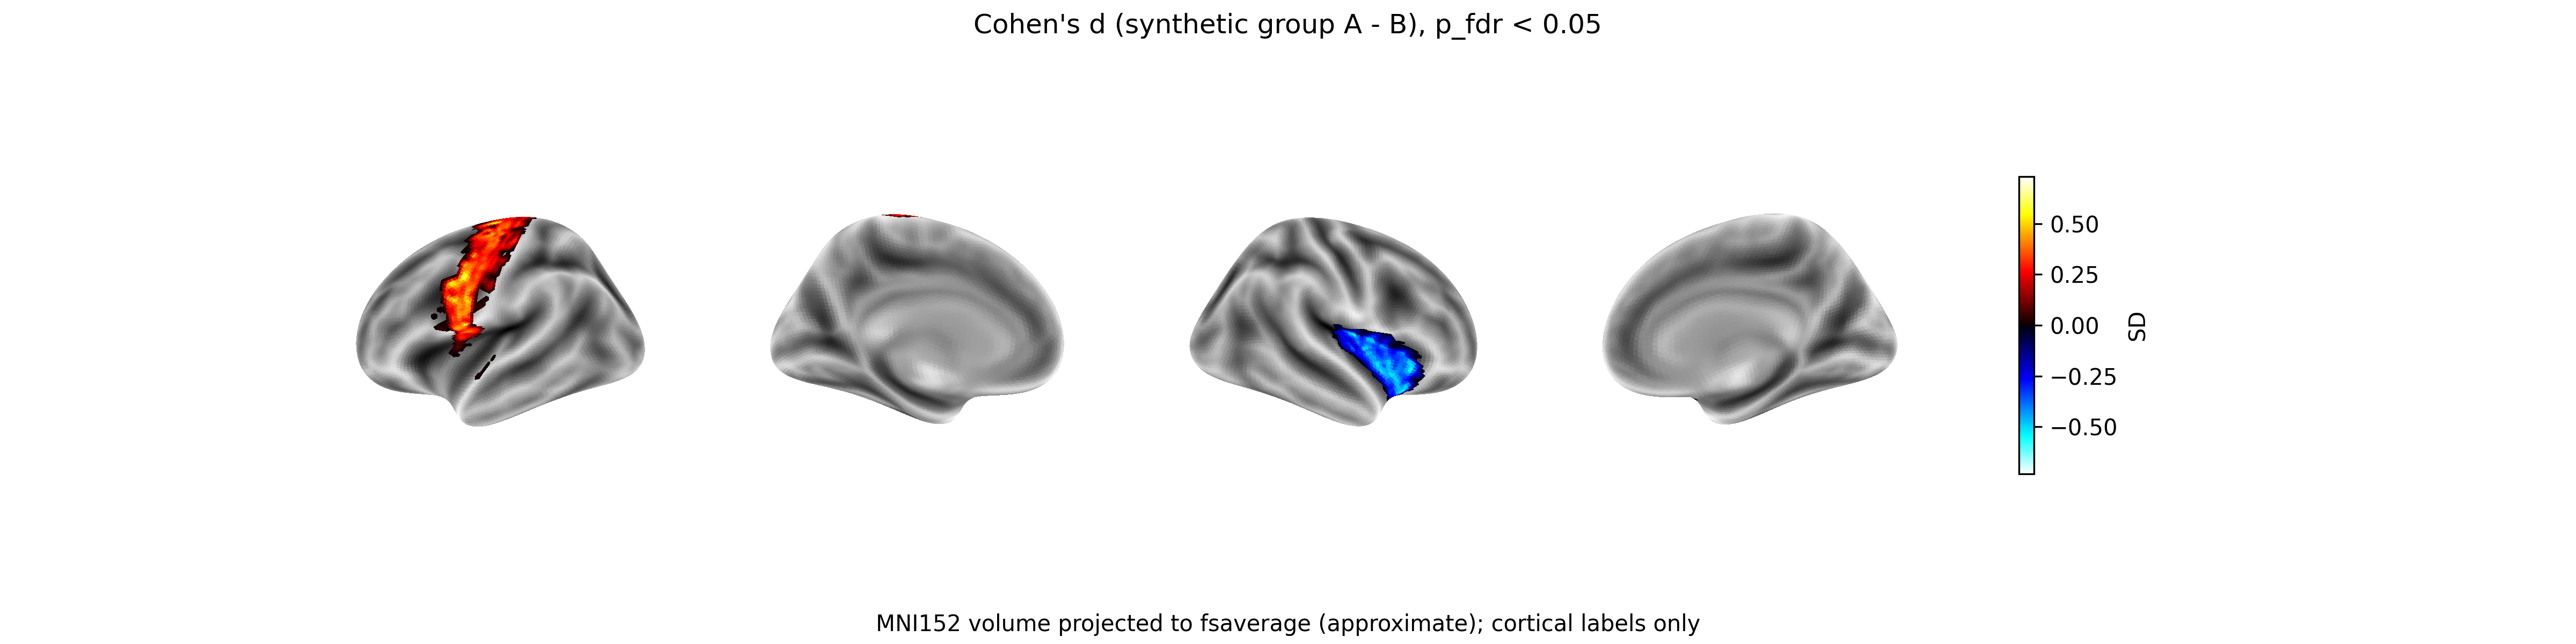

In [5]:
files = regionmap.figures(OUT / "synthetic_effects.nii.gz", OUT / "synthetic_effects.json",
                          TEMPLATE_FS / "mri" / "orig_nu.mgz", OUT / "figures", template=True)
print([f.name for f in files])
for f in files:
    if f.suffix == ".png":
        display(Image(filename=str(f), width=720))

## 5. Use it on your data

The same three calls work on a participant's own FastSurfer folder; the map is then on that participant's grid
(slices only; the glass brain and surface views assume template space):

```python
img, side = regionmap.region_map(table, Path("<fastsurfer>/<subject>/mri/aparc.DKTatlas+aseg.deep.mgz"), value="z")
```

```bash
venv_imaging/bin/python -m pie.imaging.regionmap --table my_results.csv --value z \
    --fastsurfer-dir <fastsurfer>/<subject> --out maps/<subject>_z --manifest viewer.json --reference-id mri-<image id> --repo .
```

**Cite** the template (Fonov et al. 2011, NeuroImage 54:313; TemplateFlow, Ciric et al. 2022, Nat Methods) and
FastSurfer (Henschel et al. 2020, NeuroImage 219:117012) when you publish a figure made this way. See
[brain_viewer.md](../documentation/brain_viewer.md#statistic-maps) for the rules and limits.